# Question 2)
## Part ii)

Use Euler method to estimate x(10) where $\dot{x}$ = x - 4


In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Define the ODE
def dxdt(x):
    return x - 4

In [7]:
# Numerical timestep = 1
Delta_t = 1

# Define all times when measurements will be taken
t_start = 0
t_end = 10
t = np.arange(t_start, t_end + Delta_t, Delta_t)

# Initial condition x(0) = 1
x0 = 1

# Initialise an x array to fill with solutions
X = np.zeros(t.shape)
X[0] = x0

### Euler's method 
$$x_{n+1}=x_n+\Delta t f(x_n).$$

In [9]:
# Loop Euler's method to fill up the x array.
for j in range(t.shape[0]-1):
    X[j+1] = X[j] + Delta_t * dxdt(X[j])

## Answer to part ii)

In [10]:
x_hat0 = X[-1]
print("The numerical solution with Delta_t = 1 is x(10) =", x_hat0)

The numerical solution with Delta_t = 1 is x(10) = -3068.0


## Part iii)

In [6]:
# Repeat with different values of Delta_t

# Create array of all Delta_t values to be used
dt = [10e-1, 10e-2, 10e-3, 10e-4, 10e-5]

# Create list that will hold the x value after 10 seconds for each dt value.
xhat_list = []

# Do Euler method for these Delta_t values

for delta_t in dt:
    # Define all times when measurements will be taken
    t_start = 0
    t_end = 10
    t = np.arange(t_start, t_end + delta_t, delta_t)
    
    # Initial condition x(0) = 1
    x0 = 1
    
    # Initialise an x array to fill with solutions
    x = np.zeros(t.shape)
    x[0] = x0
    
    # Loop Euler's method to fill up the x array.
    for j in range(t.shape[0]-1):
        x[j+1] = x[j] + delta_t * dxdt(x[j])

    xhat_list.append(x[-1])

In [46]:
x_hat1, x_hat2, x_hat3, x_hat4, x_hat5 = xhat_list

## Answer to part iii)

In [47]:
print("The numerical solution with Delta_t = 10e-1 is x(10) =", x_hat1)
print("The numerical solution with Delta_t = 10e-2 is x(10) =", x_hat2)
print("The numerical solution with Delta_t = 10e-3 is x(10) =", x_hat3)
print("The numerical solution with Delta_t = 10e-4 is x(10) =", x_hat4)
print("The numerical solution with Delta_t = 10e-5 is x(10) =", x_hat5)

The numerical solution with Delta_t = 10e-1 is x(10) = -3068.0
The numerical solution with Delta_t = 10e-2 is x(10) = -41337.83701946687
The numerical solution with Delta_t = 10e-3 is x(10) = -62873.466913441
The numerical solution with Delta_t = 10e-4 is x(10) = -65746.0440172352
The numerical solution with Delta_t = 10e-5 is x(10) = -66042.3681456565


## Part iv)

### Plot of En against $\Delta$t

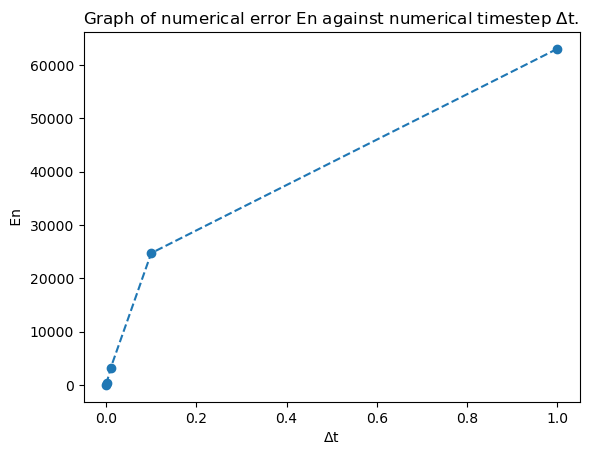

In [17]:
# Turn the answer list into a numpy array so it can be used in functions
xhat_array = np.array(xhat_list)

# Define error
En = abs(xhat_array +3*np.exp(10) - 4)

plt.plot(dt, En, "o--")
plt.title("Graph of numerical error En against numerical timestep $\Delta$t.")
plt.ylabel(" En ")
plt.xlabel("$\Delta$t");

### Plot of ln( En )  against ln( $\Delta$t )

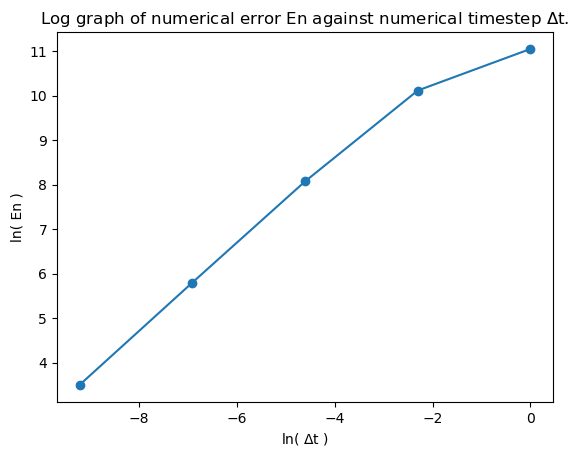

In [18]:
plt.plot( np.log(dt), np.log(En), "o-")
plt.title("Log graph of numerical error En against numerical timestep $\Delta$t.")
plt.ylabel("ln( En )")
plt.xlabel("ln( $\Delta$t )");

Not counting the data point at ln($\Delta$t) = 0, this is a linear graph of a log-log plot which means that En and $\Delta$t obey the power law En ~ $\Delta t^n$.  
The equation of a straight line is y = mx + c.   
Here, y = log(En) and x = log($\Delta$t).
So the equation of the straight line in the graph is $log(En) = n log(\Delta t) + c$.

This formula is exactly what we expect from a power law relation:
y = $x^n ==> log(y) = log(x^n) ==> log(y) = nlog(x)$.

Slope $=   \frac{rise}{run}$ = n


In [24]:
# Calculate the slope of the graph
(np.log(En)[-1] - np.log(En)[1])/(np.log(dt)[-1] - np.log(dt)[1])

0.9581527675054989

Therefore n $\approx$ 0.958 $\approx$ 1.
The error scales linearly with respect to $\Delta$t here. This is accurate as the global error of the Euler method is known to be proportional to the step size.